# F20c: Neumann-betingelser og fiktiv rand

(Forutsetter **F20a** (differanseformlene) og **F20b** (direkte løsning av RVP med Dirichlet-betingelser).) I F20b hadde vi kjente verdier $u(a)=u_a$ og $u(b)=u_b$ i *begge* endepunkter. I denne notatboken ser vi på hva som skjer når ett av endepunktene i stedet har en **Neumann-betingelse** -- altså at den *deriverte* $u'$ er kjent der, ikke $u$ selv (se kompendiets "1D -- Randverdiproblem med Neumann-betingelser").

Vi løser
$$
u'' + p\,u' + q\,u = r(x), \qquad a\le x\le b, \qquad u'(a)=u_a', \quad u(b)=u_b,
$$
altså Neumann i venstre endepunkt og Dirichlet i høyre -- akkurat som eksemplet i kompendiet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Problemet: $U_0$ er nå ukjent

I Dirichlet-tilfellet var $U_0=u_a$ rett og slett gitt, så den første ligningen i systemet var triviell: $U_0=u_a$. Nå er $u(a)$ *ikke* kjent -- bare $u'(a)$ er det. Det betyr at $U_0$ er en ekte ukjent i systemet vårt, på linje med de indre punktene, og vi trenger en ny ligning i $x_0=a$ som bruker informasjonen $u'(a)=u_a'$.

### Den naive løsningen: ensidig differanse

Det enkleste er å approksimere $u'(a)$ med en fremoverdifferanse:
$$
u_a' = \frac{u(x_1)-u(x_0)}{h} \quad\Rightarrow\quad \frac{U_1-U_0}{h} = u_a'.
$$
Dette gir en ekstra ligning -- problemet er at fremoverdifferansen bare er **førsteordens** nøyaktig ($O(h)$), mens resten av metoden (sentraldifferanser i de indre punktene) er **andreordens** ($O(h^2)$). Vi "ødelegger" dermed nøyaktigheten til hele metoden i det ene endepunktet.

Vi kunne i stedet brukt en andreordens ensidig differanse (som bruker $x_0,x_1,x_2$), men da ville ligningen for $U_0$ plutselig involvere $U_2$ også -- og vi mister den fine tridiagonale strukturen til $A$ (matrisen får et ekstra "hjørne"-element). Løsningen på dette dilemmaet er ideen om en **fiktiv rand**.

## 2. Ideen: en fiktiv rand

Vi *later som* løsningen $u$ er definert et lite stykke til *venstre* for $a$ også, i et fiktivt (ikke-fysisk) punkt
$$
x_{-1} = a - h,
$$
med en tilhørende ukjent $U_{-1}\approx u(x_{-1})$. Punktet $x_{-1}$ finnes ikke i det virkelige problemet -- det er bare et regnetriks.

Poenget er at vi nå kan behandle $x_0$ som om det var et *indre* punkt, med naboer $x_{-1}$ og $x_1$ på hver side, og bruke de vanlige (andreordens) sentraldifferansene *der* også. Det gir oss to ligninger i de to ukjente $U_{-1}$ og $U_0$:

1. Den diskretiserte ODE-en i $x_0$ (sentraldifferanser, som i de indre punktene):
$$
\frac{U_1-2U_0+U_{-1}}{h^2} + p(x_0)\frac{U_1-U_{-1}}{2h} + q(x_0)U_0 = r(x_0).
$$
2. Neumann-betingelsen, *også* med en sentraldifferanse (andreordens!) i $x_0$:
$$
\frac{U_1-U_{-1}}{2h} = u_a'.
$$

Fra ligning 2 kan vi løse ut $U_{-1} = U_1 - 2hu_a'$, og sette dette inn i ligning 1. Da forsvinner $U_{-1}$ fullstendig -- den var jo aldri en del av det virkelige problemet -- og vi sitter igjen med én ligning i de to *ekte* ukjente $U_0$ og $U_1$. Siden begge differansene vi brukte var sentrale (andreordens), beholder vi den fulle nøyaktigheten til metoden, i motsetning til den naive fremoverdifferansen over.

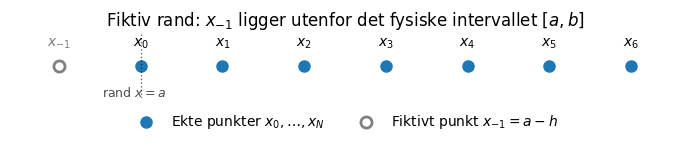

In [2]:
# Illustrasjon av gitteret med en fiktiv rand til venstre
a, b, N = 0.0, 1.0, 6
h = (b - a) / N
x = a + h*np.arange(N + 1)
x_ghost = a - h

fig, ax = plt.subplots(figsize=(7, 1.6))
ax.plot(x, np.zeros_like(x), 'o', ms=8, color='C0', label="Ekte punkter $x_0,\\ldots,x_N$")
ax.plot([x_ghost], [0], 'o', ms=8, mfc='white', mec='gray', mew=2, label="Fiktivt punkt $x_{-1}=a-h$")
for i, xi in enumerate(x):
    ax.annotate(f"$x_{{{i}}}$", (xi, 0), textcoords="offset points", xytext=(0, 14), ha='center')
ax.annotate(r"$x_{-1}$", (x_ghost, 0), textcoords="offset points", xytext=(0, 14), ha='center', color='gray')
ax.axvline(a, color='k', lw=1, ls=':', alpha=0.6)
ax.annotate("rand $x=a$", (a, 0), textcoords="offset points", xytext=(-5, -22), ha='center', fontsize=9, alpha=0.7)
ax.set_yticks([]); ax.set_xticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlim(x_ghost - h*0.6, x[-1] + h*0.6)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False)
ax.set_title("Fiktiv rand: $x_{-1}$ ligger utenfor det fysiske intervallet $[a,b]$")
plt.tight_layout()
plt.show()

## 3. Den modifiserte ligningen i $x_0$

Setter vi $U_{-1}=U_1-2hu_a'$ inn i den diskretiserte ODE-en, og rydder opp, får vi (se utledningen i kompendiet)
$$
\frac{2U_1-2U_0-2hu_a'}{h^2} + p(x_0)u_a' + q(x_0)U_0 = r(x_0).
$$
Multipliserer vi med $h^2$ og samler leddene i $U_0$ og $U_1$, blir dette
$$
\underbrace{\big({-2+h^2q(x_0)}\big)}_{=:d_0}\,U_0 \;+\; 2\,U_1 \;=\; h^2 r(x_0) + \big(2h - h^2p(x_0)\big)u_a'.
$$
Legg merke til to ting:

* **Koeffisienten til $U_0$** er nøyaktig det samme uttrykket $d=-2+h^2q$ som i de indre punktene -- bare evaluert i $x_0$.
* **Koeffisienten til $U_1$** er $2$, *ikke* $w_0=1+\tfrac h2p(x_0)$ som den ville vært i et indre punkt. Det ekstra bidraget fra $p$-leddet har havnet på høyresiden i stedet, sammen med $r(x_0)$.

Dette er fortsatt bare **én ligning med to ukjente ($U_0,U_1$)**, akkurat som en indre ligning har tre ukjente -- strukturen til $A$ forblir tridiagonal, vi har bare mistet ett av de tre leddene fordi $U_{-1}$ ikke lenger finnes.

In [3]:
def los_RVP_neumann_venstre(p, q, r_func, a, b, up_a, ub, N):
    '''Løser u'' + p u' + q u = r(x) på [a,b] med Neumann-betingelse u'(a)=up_a
    til venstre og Dirichlet-betingelse u(b)=ub til høyre, ved hjelp av en
    fiktiv rand x_{-1}=a-h for å eliminere den ukjente U_{-1} og dermed
    beholde andreordens nøyaktighet (se kompendiet).
    p, q: konstanter. r_func: funksjon r(x). N: antall delintervaller.
    Returnerer (x, U).'''
    h = (b - a) / N
    x = a + h * np.arange(N + 1)

    # Koeffisientene i de indre punktene, som i los_RVP_direkte (F20b)
    v = 1 - h / 2 * p
    d = -2 + h**2 * q
    w = 1 + h / 2 * p

    A = np.zeros((N + 1, N + 1))
    bvec = np.zeros(N + 1)

    # Rad 0: Neumann-betingelsen via fiktiv rand (se utledningen over)
    A[0, 0] = d          # samme d som i indre punkter, evaluert i x_0
    A[0, 1] = 2.0        # ikke w -- koeffisienten til U_1 er alltid 2 her
    bvec[0] = h**2 * r_func(x[0]) + (2*h - h**2 * p) * up_a

    # Rad N: triviell Dirichlet-betingelse, som i F20b
    A[N, N] = 1.0
    bvec[N] = ub

    # Indre punkter: samme diskretisering som i F20b
    for i in range(1, N):
        A[i, i - 1] = v
        A[i, i] = d
        A[i, i + 1] = w
        bvec[i] = h**2 * r_func(x[i])

    U = np.linalg.solve(A, bvec)
    return x, U


def los_RVP_neumann_venstre_naiv(p, q, r_func, a, b, up_a, ub, N):
    '''Som over, men med den naive, førsteordens fremoverdifferansen
    (U_1-U_0)/h = up_a i stedet for den fiktive randen. Brukes kun for
    å illustrere forskjellen i nøyaktighet.'''
    h = (b - a) / N
    x = a + h * np.arange(N + 1)
    v = 1 - h / 2 * p
    d = -2 + h**2 * q
    w = 1 + h / 2 * p

    A = np.zeros((N + 1, N + 1))
    bvec = np.zeros(N + 1)

    # Rad 0: (U_1-U_0)/h = up_a  <=>  -U_0 + U_1 = h*up_a
    A[0, 0] = -1.0
    A[0, 1] = 1.0
    bvec[0] = h * up_a

    A[N, N] = 1.0
    bvec[N] = ub

    for i in range(1, N):
        A[i, i - 1] = v
        A[i, i] = d
        A[i, i + 1] = w
        bvec[i] = h**2 * r_func(x[i])

    U = np.linalg.solve(A, bvec)
    return x, U

## 4. Test: eksemplet fra kompendiet

Vi viderefører eksemplet fra F20b, $u''+2u'-3u=9x$ på $[0,1]$, men bytter ut Dirichlet-betingelsen $u(0)=1$ med Neumann-betingelsen $u'(0)=-4$ (eksakt løsning er fortsatt $u(x)=e^{-3x}+2e^x-3x-2$, siden $u'(0)=-3\cdot1+2-3=-4$ for nettopp denne løsningen). Med $N=4$ skal vi få $U_0\approx0.92103219$, $U_1\approx0.25737896$, $U_2\approx0.01029386$, $U_3\approx0.08858688$ -- akkurat som i kompendiet.

In [4]:
def u_eksakt(x):
    return np.exp(-3*x) + 2*np.exp(x) - 3*x - 2

up_a = -4.0            # u'(0), gitt
ub = u_eksakt(1.0)      # u(1), gitt

x, U = los_RVP_neumann_venstre(p=2, q=-3, r_func=lambda x: 9*x, a=0, b=1, up_a=up_a, ub=ub, N=4)

print("x  :", np.round(x, 4))
print("U  :", np.round(U, 8))
print("u  :", np.round(u_eksakt(x), 8))

fasit = [0.92103219, 0.25737896, 0.01029386, 0.08858688]
print("Stemmer dette med kompendiets U_0..U_3?", np.allclose(U[:4], fasit, atol=1e-6))

x  : [0.   0.25 0.5  0.75 1.  ]
U  : [0.92103219 0.25737896 0.01029386 0.08858688 0.48635073]
u  : [1.         0.29041739 0.0205727  0.08939926 0.48635073]
Stemmer dette med kompendiets U_0..U_3? True


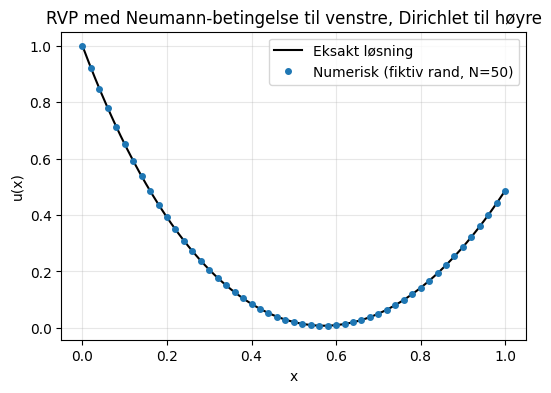

In [5]:
# Samme eksempel, men med flere punkter, plottet mot den eksakte løsningen
x_fin, U_fin = los_RVP_neumann_venstre(p=2, q=-3, r_func=lambda x: 9*x, a=0, b=1, up_a=up_a, ub=ub, N=50)
x_plot = np.linspace(0, 1, 400)

plt.figure(figsize=(6, 4))
plt.plot(x_plot, u_eksakt(x_plot), 'k-', label="Eksakt løsning")
plt.plot(x_fin, U_fin, 'o', ms=4, label="Numerisk (fiktiv rand, N=50)")
plt.xlabel("x"); plt.ylabel("u(x)")
plt.title("RVP med Neumann-betingelse til venstre, Dirichlet til høyre")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 5. Lønner den fiktive randen seg? Konvergensorden

Kompendiet påstår at metoden med fiktiv rand "fortsatt er like god som" Dirichlet-metoden fra F20b, altså andreordens ($O(h^2)$), mens den naive fremoverdifferansen bare er $O(h)$. Vi sjekker dette ved å regne ut maksimal feil $\max_i|U_i-u(x_i)|$ for en rekke verdier av $N$, og se hvor fort feilen avtar når $h$ halveres.

Estimert konvergensorden, fiktiv rand:        1.99  (forventet 2)
Estimert konvergensorden, naiv fremoverdiff.: 1.03  (forventet 1)


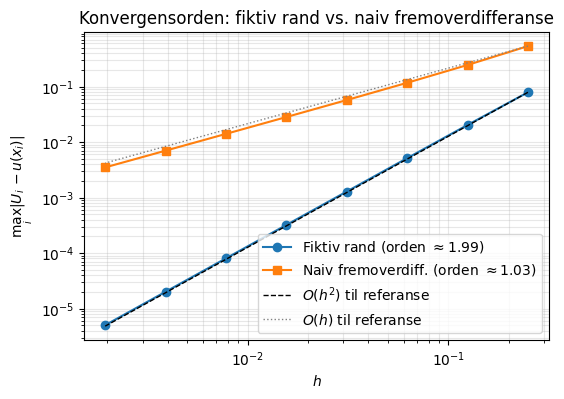

In [6]:
Ns = np.array([4, 8, 16, 32, 64, 128, 256, 512])
hs = (1.0 - 0.0) / Ns

feil_fiktiv = []
feil_naiv = []
for N in Ns:
    x, U = los_RVP_neumann_venstre(p=2, q=-3, r_func=lambda x: 9*x, a=0, b=1, up_a=up_a, ub=ub, N=N)
    feil_fiktiv.append(np.max(np.abs(U - u_eksakt(x))))

    x2, U2 = los_RVP_neumann_venstre_naiv(p=2, q=-3, r_func=lambda x: 9*x, a=0, b=1, up_a=up_a, ub=ub, N=N)
    feil_naiv.append(np.max(np.abs(U2 - u_eksakt(x2))))

feil_fiktiv = np.array(feil_fiktiv)
feil_naiv = np.array(feil_naiv)

# Estimer konvergensorden som stigningstallet til log(feil) mot log(h)
orden_fiktiv = np.polyfit(np.log(hs), np.log(feil_fiktiv), 1)[0]
orden_naiv = np.polyfit(np.log(hs), np.log(feil_naiv), 1)[0]
print(f"Estimert konvergensorden, fiktiv rand:        {orden_fiktiv:.2f}  (forventet 2)")
print(f"Estimert konvergensorden, naiv fremoverdiff.: {orden_naiv:.2f}  (forventet 1)")

plt.figure(figsize=(6, 4))
plt.loglog(hs, feil_fiktiv, 'o-', label=f"Fiktiv rand (orden $\\approx${orden_fiktiv:.2f})")
plt.loglog(hs, feil_naiv, 's-', label=f"Naiv fremoverdiff. (orden $\\approx${orden_naiv:.2f})")
plt.loglog(hs, feil_fiktiv[0]*(hs/hs[0])**2, 'k--', lw=1, label="$O(h^2)$ til referanse")
plt.loglog(hs, feil_naiv[0]*(hs/hs[0])**1, 'gray', ls=':', lw=1, label="$O(h)$ til referanse")
plt.xlabel("$h$"); plt.ylabel(r"$\max_i|U_i-u(x_i)|$")
plt.title("Konvergensorden: fiktiv rand vs. naiv fremoverdifferanse")
plt.legend(); plt.grid(alpha=0.3, which='both')
plt.show()

Feilkurven for fremoverdifferansen flater klart mindre bratt ut enn $O(h^2)$-kurven -- den følger i stedet $O(h)$-linjen. Den fiktive randen gjenoppretter andreordens konvergens i hele intervallet, akkurat som påstått i kompendiet, selv om vi bare brukte den til å håndtere *ett* av endepunktene annerledes.

## Oppsummering

* Når et endepunkt har en Neumann-betingelse ($u'$ kjent, ikke $u$), blir $U_0$ (eller $U_N$) en ekte ukjent, og vi trenger en ekstra ligning der.
* En naiv ensidig (fremover-)differanse gir riktignok en ekstra ligning, men bare $O(h)$-nøyaktighet -- dårligere enn resten av metoden.
* Triks: innfør en **fiktiv rand** $x_{-1}=a-h$ utenfor domenet, skriv opp sentraldifferanser for *både* ODE-en og Neumann-betingelsen i $x_0$, og **eliminer** den fiktive ukjente $U_{-1}$ mellom de to ligningene.
* Resultatet er én ligning i $x_0$ som involverer kun $U_0$ og $U_1$ -- matrisen $A$ forblir tridiagonal, og metoden beholder full $O(h^2)$-nøyaktighet.
* Robin-betingelser (en kombinasjon av $u$ og $u'$) håndteres på akkurat samme måte, med samme fiktive rand-triks (se kompendiet).